# Telco Customer Intelligence (DemoTel)
One notebook for the whole project. Every step is recorded here, in order.

| Part | Content | Status |
|---|---|---|
| 1 | Data assessment | done (E/F/G are yours) |
| 2 | Cleaning + tests | done |
| 3 | EDA | done |
| 4 | Statistics (tests, survival, segments) | done |
| 5 | Churn model | done |
| 6 | Evaluation on held-out test set | done |
| 7 | Model benchmark (9 models, nested CV) | done |
| 8 | Agents / RAG | |
| 9 | Evals & monitoring | |

Source: Kaggle CSV only (`data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv`).

## Part 1 · Data assessment
### Setup & load

In [1]:
import sys; sys.path.insert(0, "../src")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### A. Structure, types, missing values

In [2]:
print(df.shape)
df.dtypes.to_frame('dtype').T

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


In [3]:
# Looks clean... but is it?
df.isna().sum().sum()

np.int64(0)

In [4]:
# TotalCharges is text: find what is not a number
bad = df[pd.to_numeric(df.TotalCharges, errors='coerce').isna()]
print(len(bad), "non-numeric TotalCharges; distinct raw values:", bad.TotalCharges.unique())
bad[['customerID','tenure','MonthlyCharges','TotalCharges','Contract','Churn']]

11 non-numeric TotalCharges; distinct raw values: <StringArray>
[' ']
Length: 1, dtype: str


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [5]:
# Who are they? Compare with every customer who has tenure == 0
print("tenure == 0 overall:", (df.tenure == 0).sum(), "| of those with blank TotalCharges:", (bad.tenure == 0).sum())
print(bad.Churn.value_counts().to_dict(), bad.Contract.value_counts().to_dict())

tenure == 0 overall: 11 | of those with blank TotalCharges: 11
{'No': 11} {'Two year': 10, 'One year': 1}


In [6]:
print("customerID unique:", df.customerID.is_unique)
print("duplicate rows ignoring ID:", df.drop(columns='customerID').duplicated().sum())

customerID unique: True
duplicate rows ignoring ID: 22


### B. Target and balance

{'No': 5174, 'Yes': 1869} -> churn rate 26.5%


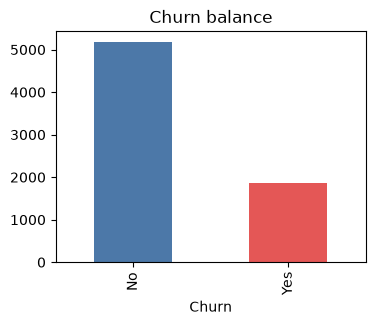

In [7]:
vc = df.Churn.value_counts(); print(vc.to_dict(), f"-> churn rate {vc['Yes']/len(df):.1%}")
fig, ax = plt.subplots(figsize=(4,3)); vc.plot.bar(ax=ax, color=['#4c78a8','#e45756']); ax.set_title('Churn balance'); plt.show()

In [8]:
# Quick look: churn rate by the usual suspects
for c in ['Contract','PaymentMethod','InternetService','SeniorCitizen']:
    print(df.groupby(c).Churn.apply(lambda s: (s=='Yes').mean()).round(3).to_frame('churn_rate').assign(n=df[c].value_counts())); print()

                churn_rate     n
Contract                        
Month-to-month       0.427  3875
One year             0.113  1473
Two year             0.028  1695

                           churn_rate     n
PaymentMethod                              
Bank transfer (automatic)       0.167  1544
Credit card (automatic)         0.152  1522
Electronic check                0.453  2365
Mailed check                    0.191  1612

                 churn_rate     n
InternetService                  
DSL                   0.190  2421
Fiber optic           0.419  3096
No                    0.074  1526

               churn_rate     n
SeniorCitizen                  
0                   0.236  5901
1                   0.417  1142



### C. Leakage hunt
A leaking column is one that is only known *because* the customer churned, or is computed from the target. Check the values that look suspicious.

In [9]:
# Can TotalCharges be rebuilt from tenure x MonthlyCharges? Large gaps show price changes or add-ons over time.
d = df.assign(tc=pd.to_numeric(df.TotalCharges, errors='coerce'))
d['gap'] = d.tc - d.tenure * d.MonthlyCharges
print(d.gap.describe().round(1))
print("correlation tenure vs TotalCharges:", round(d.tenure.corr(d.tc), 3))

count    7032.0
mean        0.2
std        67.3
min      -370.8
25%       -28.6
50%         0.0
75%        28.7
max       373.3
Name: gap, dtype: float64
correlation tenure vs TotalCharges: 0.826


In [10]:
# Does any single column almost perfectly predict Churn? (should NOT happen without leakage)
pred = {c: df.groupby(c).Churn.apply(lambda s: (s=='Yes').mean()).max() for c in df.columns if df[c].nunique() <= 10 and c != 'Churn'}
pd.Series(pred).sort_values(ascending=False).round(3).to_frame('max churn rate in one level')

,max churn rate in one level
PaymentMethod,0.453
Contract,0.427
InternetService,0.419
OnlineSecurity,0.418
SeniorCitizen,0.417
TechSupport,0.416
OnlineBackup,0.399
DeviceProtection,0.391
StreamingMovies,0.337
PaperlessBilling,0.336


### D. Constant / useless columns, cardinality

In [11]:
df.nunique().sort_values().to_frame('unique values').T

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,Churn,MultipleLines,TechSupport,StreamingTV,OnlineBackup,DeviceProtection,StreamingMovies,Contract,OnlineSecurity,InternetService,PaymentMethod,tenure,MonthlyCharges,TotalCharges,customerID
unique values,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,3,4,73,1585,6531,7043


In [12]:
# Redundant levels
for c in ['MultipleLines','OnlineSecurity','StreamingTV']:
    print(c, df[c].value_counts().to_dict())

MultipleLines {'No': 3390, 'Yes': 2971, 'No phone service': 682}
OnlineSecurity {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
StreamingTV {'No': 2810, 'Yes': 2707, 'No internet service': 1526}


### Distributions of the numeric columns

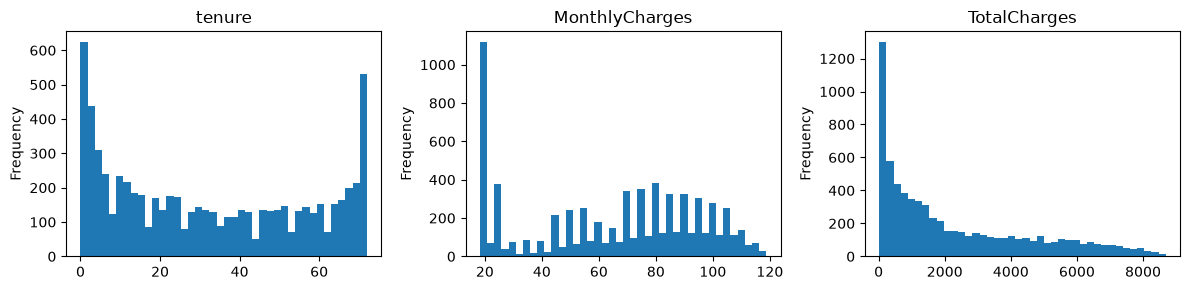

,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7032.0
mean,32.4,64.8,2283.3
std,24.6,30.1,2266.8
min,0.0,18.2,18.8
25%,9.0,35.5,401.4
50%,29.0,70.4,1397.5
75%,55.0,89.8,3794.7
max,72.0,118.8,8684.8


In [13]:
d = df.assign(TotalCharges=pd.to_numeric(df.TotalCharges, errors='coerce'))
fig, axs = plt.subplots(1, 3, figsize=(12,3))
for ax, c in zip(axs, ['tenure','MonthlyCharges','TotalCharges']):
    d[c].plot.hist(bins=40, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()
d[['tenure','MonthlyCharges','TotalCharges']].describe().round(1)

### E. Fit for each module · F. Limitations · G. License
*(your write-up, see `notes/data_assessment.md`)*

## Part 2 · Cleaning + tests
`clean()` lives in `src/telco/cleaning.py` so tests and later modules can import it. Here it is, then the tests, then proof on the real data.

In [14]:
import inspect
from telco.cleaning import clean
print(inspect.getsource(clean))

def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Return a cleaned copy of the raw Telco churn table.

    - TotalCharges: text -> float. Blank means "no bill yet", which only
      happens for tenure == 0 customers, so it becomes 0.0. A blank anywhere
      else is a real data problem and raises.
    - Churn: "Yes"/"No" -> 1/0.
    """
    out = df.copy()

    total = pd.to_numeric(out["TotalCharges"], errors="coerce")
    unexplained = total.isna() & (out["tenure"] > 0)
    if unexplained.any():
        raise ValueError(f"{unexplained.sum()} blank TotalCharges with tenure > 0")
    out["TotalCharges"] = total.fillna(0.0)

    churn = out["Churn"].map({"Yes": 1, "No": 0})
    if churn.isna().any():
        raise ValueError("Churn has values other than Yes/No")
    out["Churn"] = churn.astype(int)

    return out



Tests (`tests/test_cleaning.py`), run with pytest from this notebook:

In [15]:
print(open("../tests/test_cleaning.py").read())

import pandas as pd
import pytest

from telco.cleaning import clean


def raw(**overrides):
    base = {
        "customerID": ["a", "b", "c"],
        "tenure": [0, 5, 12],
        "TotalCharges": [" ", "100.5", "800"],
        "Churn": ["No", "Yes", "No"],
    }
    return pd.DataFrame({**base, **overrides})


def test_totalcharges_becomes_float_and_blank_new_customer_is_zero():
    out = clean(raw())
    assert out["TotalCharges"].dtype == float
    assert out["TotalCharges"].tolist() == [0.0, 100.5, 800.0]


def test_no_missing_values_remain():
    assert clean(raw()).isna().sum().sum() == 0


def test_blank_totalcharges_with_tenure_raises():
    with pytest.raises(ValueError, match="blank TotalCharges"):
        clean(raw(TotalCharges=[" ", " ", "800"]))


def test_churn_is_zero_one_and_unknown_label_raises():
    assert clean(raw())["Churn"].tolist() == [0, 1, 0]
    with pytest.raises(ValueError, match="Churn"):
        clean(raw(Churn=["No", "Maybe", "No"]))


def test_input_is

In [16]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "-p", "no:cacheprovider"], cwd="..", capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-500:])

.py::test_every_candidate_fits_and_returns_valid_probabilities PASSED [  7%]
tests/test_benchmark.py::test_candidate_set_has_the_requested_families PASSED [ 15%]
tests/test_cleaning.py::test_totalcharges_becomes_float_and_blank_new_customer_is_zero PASSED [ 23%]
tests/test_cleaning.py::test_no_missing_values_remain PASSED             [ 30%]
tests/test_cleaning.py::test_blank_totalcharges_with_tenure_raises PASSED [ 38%]
tests/test_cleaning.py::test_churn_is_zero_one_and_unknown_label_raises PASSED [ 46%]
tests/test_cleaning.py::test_input_is_not_modified_and_rows_are_kept PASSED [ 53%]
tests/test_model.py::test_split_is_disjoint_stratified_and_has_no_target_or_id PASSED [ 61%]
tests/test_model.py::test_add_features_counts_addons_and_handles_tenure_zero PASSED [ 69%]
tests/test_model.py::test_pipeline_fits_and_survives_unseen_category[logistic_pipeline] PASSED [ 76%]
tests/test_model.py::test_pipeline_fits_and_survives_unseen_category[lgbm_pipeline] PASSED [ 84%]
tests/test_model.py::te

The real-file check: the original problems (`TotalCharges` as text, hidden blanks) must be gone and nothing else may change.

In [17]:
clean_df = clean(df)
checks = {
    "same row count": len(clean_df) == len(df),
    "TotalCharges is float": clean_df.TotalCharges.dtype == float,
    "no missing values": clean_df.isna().sum().sum() == 0,
    "11 zero TotalCharges, all tenure 0": ((clean_df.TotalCharges == 0).sum() == 11) and (clean_df.loc[clean_df.TotalCharges == 0, "tenure"] == 0).all(),
    "Churn is 0/1, rate unchanged": set(clean_df.Churn) == {0, 1} and abs(clean_df.Churn.mean() - 0.2654) < 1e-3,
    "other columns untouched": df.drop(columns=["TotalCharges", "Churn"]).equals(clean_df.drop(columns=["TotalCharges", "Churn"])),
}
pd.Series(checks, name="passed").to_frame()

,passed
same row count,True
TotalCharges is float,True
no missing values,True
"11 zero TotalCharges, all tenure 0",True
"Churn is 0/1, rate unchanged",True
other columns untouched,True


## Part 3 · Exploratory data analysis
All charts use the cleaned table. Goal: see where churn concentrates before testing anything formally. Differences here are *descriptions*, not proof; Part 4 tests them.

In [18]:
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
BASE = clean_df.Churn.mean()
def rate_by(col):
    return clean_df.groupby(col).Churn.agg(["mean", "size"]).sort_values("mean")
def bar_rate(col, ax, title=None):
    r = rate_by(col)
    ax.barh(r.index.astype(str), r["mean"], color="#4c78a8")
    ax.axvline(BASE, color="#e45756", ls="--", lw=1); ax.set_xlim(0, 0.7)
    for y, (m, n) in enumerate(zip(r["mean"], r["size"])): ax.text(m + 0.01, y, f"{m:.0%}  (n={n:,})", va="center", fontsize=8)
    ax.set_title(title or col); ax.set_xlabel("churn rate")
print(f"overall churn rate (dashed line): {BASE:.1%}")

overall churn rate (dashed line): 26.5%


### 1 · Contract, payment method, internet service

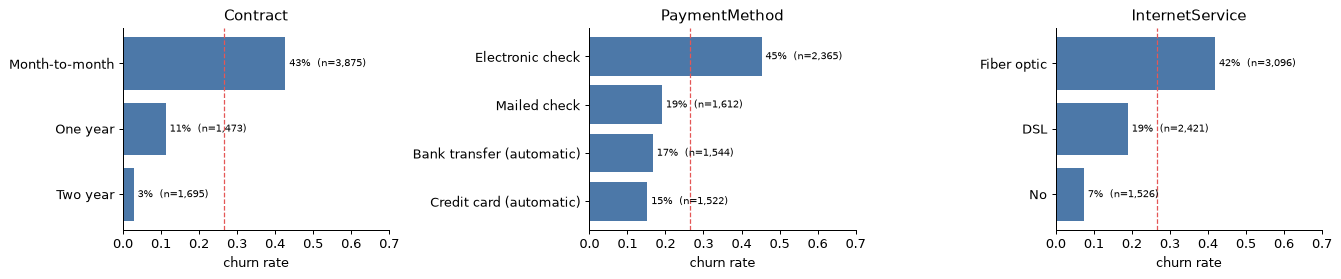

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.2))
bar_rate("Contract", axs[0]); bar_rate("PaymentMethod", axs[1]); bar_rate("InternetService", axs[2])
plt.tight_layout(); plt.show()

### 2 · Tenure: when do customers leave?

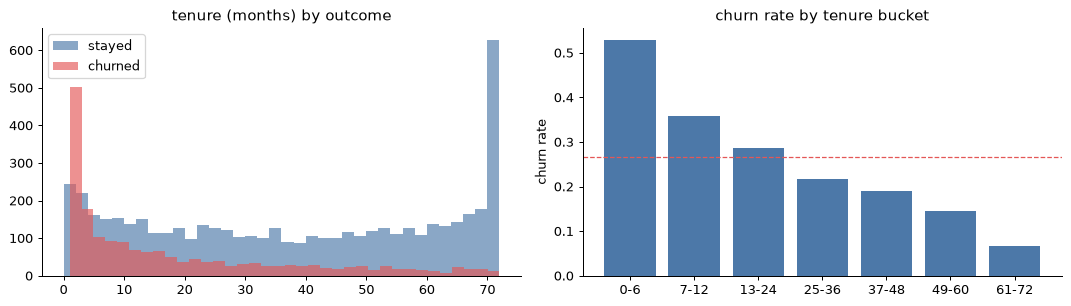

{'0-6': 0.529, '7-12': 0.359, '13-24': 0.287, '25-36': 0.216, '37-48': 0.19, '49-60': 0.144, '61-72': 0.066}


In [20]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for v, c in [(0, "#4c78a8"), (1, "#e45756")]:
    axs[0].hist(clean_df[clean_df.Churn == v].tenure, bins=36, alpha=.65, color=c, label="churned" if v else "stayed")
axs[0].set_title("tenure (months) by outcome"); axs[0].legend()
b = pd.cut(clean_df.tenure, [-1, 6, 12, 24, 36, 48, 60, 72], labels=["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
r = clean_df.groupby(b, observed=True).Churn.mean()
axs[1].bar(r.index.astype(str), r.values, color="#4c78a8"); axs[1].axhline(BASE, color="#e45756", ls="--", lw=1)
axs[1].set_title("churn rate by tenure bucket"); axs[1].set_ylabel("churn rate")
plt.tight_layout(); plt.show()
print(r.round(3).to_dict())

### 3 · Money: monthly charges

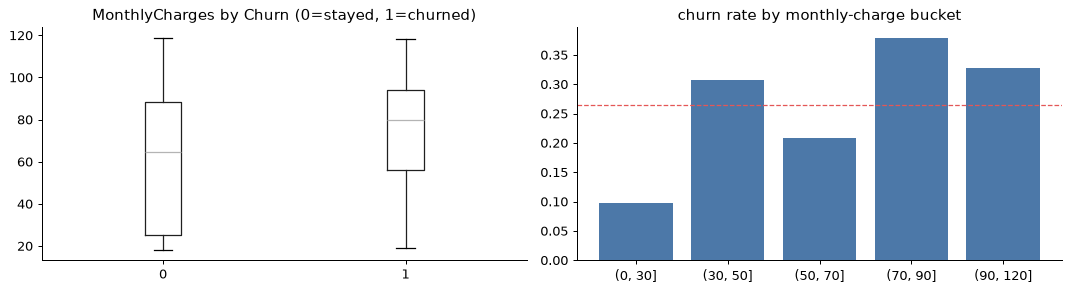

       mean  median
Churn              
0      61.3    64.4
1      74.4    79.6


In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
clean_df.boxplot(column="MonthlyCharges", by="Churn", ax=axs[0], grid=False); axs[0].set_title("MonthlyCharges by Churn (0=stayed, 1=churned)"); axs[0].set_xlabel("")
b = pd.cut(clean_df.MonthlyCharges, [0, 30, 50, 70, 90, 120])
r = clean_df.groupby(b, observed=True).Churn.agg(["mean", "size"])
axs[1].bar(r.index.astype(str), r["mean"], color="#4c78a8"); axs[1].axhline(BASE, color="#e45756", ls="--", lw=1); axs[1].set_title("churn rate by monthly-charge bucket")
plt.suptitle(""); plt.tight_layout(); plt.show()
print(clean_df.groupby("Churn").MonthlyCharges.agg(["mean", "median"]).round(1))

### 4 · Add-on services: does support reduce churn? (internet customers only)

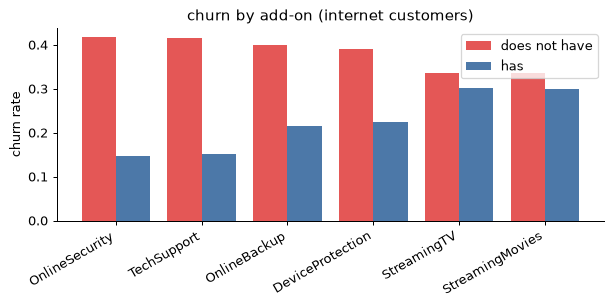

,No,Yes
OnlineSecurity,0.418,0.146
TechSupport,0.416,0.152
OnlineBackup,0.399,0.215
DeviceProtection,0.391,0.225
StreamingTV,0.335,0.301
StreamingMovies,0.337,0.299


In [22]:
net = clean_df[clean_df.InternetService != "No"]
svc = ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]
res = pd.DataFrame({s: net.groupby(s).Churn.mean() for s in svc}).T[["No", "Yes"]]
fig, ax = plt.subplots(figsize=(7, 3.5)); x = np.arange(len(svc))
ax.bar(x - .2, res["No"], .4, label="does not have", color="#e45756"); ax.bar(x + .2, res["Yes"], .4, label="has", color="#4c78a8")
ax.set_xticks(x); ax.set_xticklabels(svc, rotation=30, ha="right"); ax.set_ylabel("churn rate"); ax.legend(); ax.set_title("churn by add-on (internet customers)")
plt.tight_layout(); plt.show(); res.round(3)

### 5 · Who they are: demographics

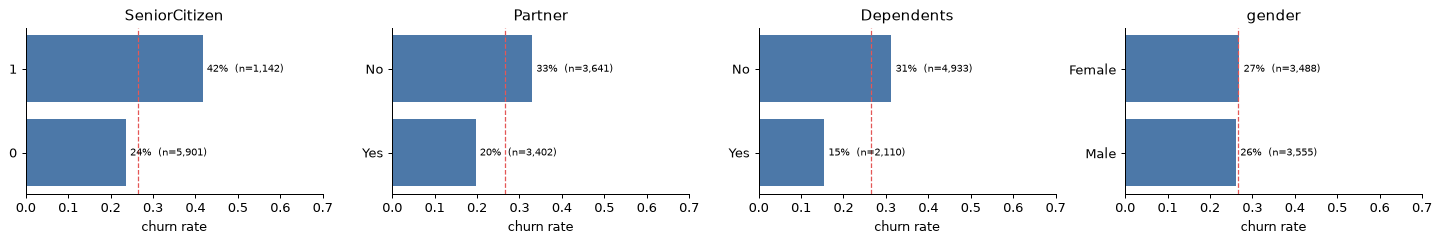

In [23]:
fig, axs = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, col in zip(axs, ["SeniorCitizen", "Partner", "Dependents", "gender"]): bar_rate(col, ax)
plt.tight_layout(); plt.show()

### 6 · Combinations: is Fiber the problem, or the contract it comes with?

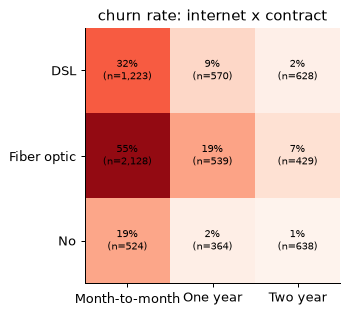

In [24]:
pt = clean_df.pivot_table(index="InternetService", columns="Contract", values="Churn", aggfunc="mean")
cnt = clean_df.pivot_table(index="InternetService", columns="Contract", values="Churn", aggfunc="size")
fig, ax = plt.subplots(figsize=(8, 3.6)); im = ax.imshow(pt.values, cmap="Reds", vmin=0, vmax=.6)
ax.set_xticks(range(3)); ax.set_xticklabels(pt.columns); ax.set_yticks(range(3)); ax.set_yticklabels(pt.index)
for i in range(3):
    for j in range(3): ax.text(j, i, f"{pt.values[i,j]:.0%}" + chr(10) + f"(n={cnt.values[i,j]:,})", ha="center", va="center", fontsize=8)
ax.set_title("churn rate: internet x contract"); plt.tight_layout(); plt.show()

### 7 · Share of customers vs share of churners (where the volume is)

In [25]:
g = clean_df.assign(profile=np.where(clean_df.Contract == "Month-to-month", "month-to-month", "1-2 year contract"))
s = g.groupby("profile").agg(customers=("Churn", "size"), churners=("Churn", "sum"))
s["% of customers"] = (s.customers / s.customers.sum()).round(3); s["% of churners"] = (s.churners / s.churners.sum()).round(3)
s

,customers,churners,% of customers,% of churners
profile,,,,
1-2 year contract,3168,214,0.45,0.114
month-to-month,3875,1655,0.55,0.886


### 8 · Monthly revenue lost to churn

In [26]:
lost = clean_df[clean_df.Churn == 1].MonthlyCharges.sum(); total = clean_df.MonthlyCharges.sum()
print(f"monthly revenue from churned customers: {lost:,.0f} of {total:,.0f} ({lost/total:.1%})")
print(clean_df[clean_df.Churn == 1].groupby("Contract").MonthlyCharges.sum().round(0).to_dict())

monthly revenue from churned customers: 139,131 of 456,117 (30.5%)
{'Month-to-month': 120847.0, 'One year': 14118.0, 'Two year': 4165.0}


### What the EDA shows (descriptions, not proof)
1. **Contract is the biggest split.** Month-to-month churns at 43%, one-year 11%, two-year 3%. Month-to-month customers are 55% of the base but **89% of churners**.
2. **Early tenure is the danger zone.** Churn is 53% in months 0-6 and falls steadily to 7% after month 60. Most of the loss is customers who never settle in.
3. **Fiber looks bad, but contract explains much of it.** Fiber churns at 42% overall, yet fiber customers on a one-year contract churn at 19% and two-year at 7%. Fiber + month-to-month is the hot spot (55%, n=2,128).
4. **Electronic-check payers churn at 45%**, against 15-19% for every other method. Automatic payment is not obviously the cause (it is also tied to contract type and tenure), so this needs controlling for in Part 4, not a "switch them to autopay" conclusion yet.
5. **Churners pay more:** mean monthly charge 74.4 vs 61.3 (median 79.6 vs 64.4).
6. **Support add-ons matter, streaming does not.** Among internet customers, without OnlineSecurity churn is 42% vs 15% with it; TechSupport 42% vs 15%. Streaming TV/Movies barely differ (33-34% vs 30%).
7. **Demographics:** senior citizens 42% vs 24%; having a partner (20% vs 33%) or dependents (15% vs 31%) lowers churn; gender makes no difference (27% vs 26%).
8. **Money:** customers who churned account for 139,131 of 456,117 monthly revenue (30.5%), and 121k of that 139k is month-to-month.

**Caution:** contract, tenure, price, internet type and payment method overlap heavily. Every "X causes churn" reading above is unproven until the tests and the model control for the others.

## Part 4 · Statistics
EDA described differences; here we test them. Three questions: (1) is each difference bigger than chance, (2) how big is it (effect size), (3) does it survive controlling for the other variables.

### 4.1 Chi-square: categorical features vs churn
With 7,043 rows almost everything is 'significant', so the **effect size (Cramér's V)** is what ranks the features. p-values are Holm-corrected for the 16 tests.

In [27]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
cats = [c for c in clean_df.columns if c not in ("customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges")]
rows = []
for c in cats:
    ct = pd.crosstab(clean_df[c], clean_df.Churn)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append((c, chi2, dof, p, v))
chi = pd.DataFrame(rows, columns=["feature", "chi2", "dof", "p", "cramers_v"])
chi["p_holm"] = multipletests(chi.p, method="holm")[1]
chi["significant"] = chi.p_holm < 0.05
chi = chi.sort_values("cramers_v", ascending=False).reset_index(drop=True)
chi.round({"chi2": 1, "p": 4, "p_holm": 4, "cramers_v": 3})

,feature,chi2,dof,p,cramers_v,p_holm,significant
0,Contract,1184.6,2,0.0000,0.410,0.0000,True
1,OnlineSecurity,850.0,2,0.0000,0.347,0.0000,True
2,TechSupport,828.2,2,0.0000,0.343,0.0000,True
3,InternetService,732.3,2,0.0000,0.322,0.0000,True
4,PaymentMethod,648.1,3,0.0000,0.303,0.0000,True
5,OnlineBackup,601.8,2,0.0000,0.292,0.0000,True
6,DeviceProtection,558.4,2,0.0000,0.282,0.0000,True
7,StreamingMovies,375.7,2,0.0000,0.231,0.0000,True
8,StreamingTV,374.2,2,0.0000,0.231,0.0000,True
9,PaperlessBilling,258.3,1,0.0000,0.191,0.0000,True


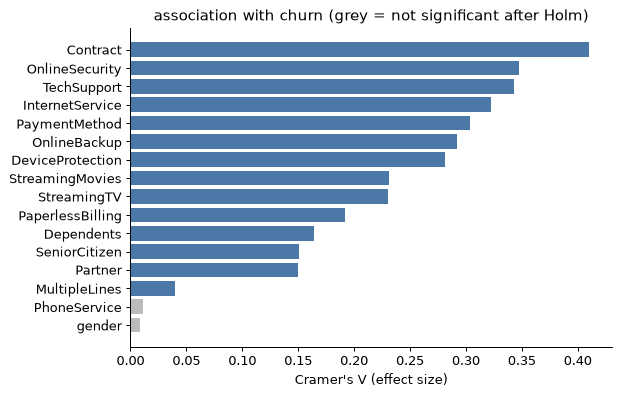

In [28]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(chi.feature[::-1], chi.cramers_v[::-1], color=["#4c78a8" if s else "#bbbbbb" for s in chi.significant[::-1]])
ax.set_xlabel("Cramer's V (effect size)"); ax.set_title("association with churn (grey = not significant after Holm)")
plt.tight_layout(); plt.show()

### 4.2 Mann-Whitney: numeric features, churned vs stayed
The numeric columns are skewed and tenure is U-shaped (see EDA), so a rank test is safer than a t-test. Effect size is the rank-biserial correlation r (0 = no difference, +1 = churners always higher).

In [29]:
rows = []
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    a, b = clean_df[clean_df.Churn == 1][c], clean_df[clean_df.Churn == 0][c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append((c, a.median(), b.median(), p, 2 * u / (len(a) * len(b)) - 1))
mw = pd.DataFrame(rows, columns=["feature", "median_churned", "median_stayed", "p", "rank_biserial_r"])
mw["p_holm"] = multipletests(mw.p, method="holm")[1]
mw.round(4)

,feature,median_churned,median_stayed,p,rank_biserial_r,p_holm
0,tenure,10.00,38.000,0.0,-0.4797,0.0
1,MonthlyCharges,79.65,64.425,0.0,0.2416,0.0
2,TotalCharges,703.55,1679.525,0.0,-0.3007,0.0


### 4.3 Does 'Fiber' still matter after controlling for contract, tenure and price?
First, the simple stratified check: fiber vs DSL *within* each contract type.

In [30]:
sub = clean_df[clean_df.InternetService.isin(["Fiber optic", "DSL"])]
rows = []
for k, g in sub.groupby("Contract"):
    ct = pd.crosstab(g.InternetService, g.Churn)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append((k, g[g.InternetService == "DSL"].Churn.mean(), g[g.InternetService == "Fiber optic"].Churn.mean(), p))
pd.DataFrame(rows, columns=["contract", "DSL churn", "Fiber churn", "p"]).round(4)

,contract,DSL churn,Fiber churn,p
0,Month-to-month,0.3222,0.5461,0.0
1,One year,0.0930,0.1929,0.0
2,Two year,0.0191,0.0723,0.0


Then a logistic regression with several variables together. Odds ratio above 1 = higher odds of churn, holding the other variables fixed.

In [31]:
import statsmodels.formula.api as smf
m = smf.logit("Churn ~ C(Contract) + C(InternetService) + C(PaymentMethod) + tenure + MonthlyCharges + SeniorCitizen + C(Partner) + C(Dependents) + C(PaperlessBilling)", data=clean_df).fit(disp=0)
ci = np.exp(m.conf_int())
orr = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_low": ci[0], "ci_high": ci[1], "p": m.pvalues}).drop("Intercept")
print("pseudo R2:", round(m.prsquared, 3))
orr.round(3)

pseudo R2: 0.269


,odds_ratio,ci_low,ci_high,p
C(Contract)[T.One year],0.486,0.396,0.597,0.000
C(Contract)[T.Two year],0.227,0.162,0.318,0.000
C(InternetService)[T.Fiber optic],2.379,1.845,3.067,0.000
C(InternetService)[T.No],0.488,0.362,0.658,0.000
C(PaymentMethod)[T.Credit card (automatic)],0.918,0.736,1.145,0.448
C(PaymentMethod)[T.Electronic check],1.493,1.244,1.791,0.000
C(PaymentMethod)[T.Mailed check],0.960,0.771,1.196,0.718
C(Partner)[T.Yes],1.011,0.870,1.175,0.887
C(Dependents)[T.Yes],0.823,0.692,0.979,0.028
C(PaperlessBilling)[T.Yes],1.488,1.290,1.717,0.000


### 4.4 Survival: how long do customers last? (Kaplan-Meier)
Every customer is observed for `tenure` months. Churners are *events*; customers still active are **censored** (we only know they lasted at least that long). Ignoring censoring would understate how long customers stay.

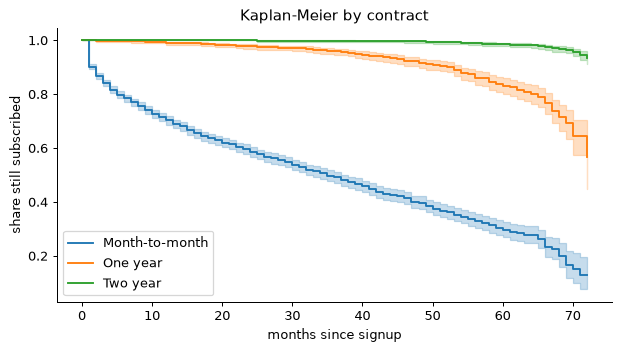

log-rank test across contracts: chi2 = 2352.9 p = 0.0


,S(6m),S(12m),S(24m),S(48m),median
Month-to-month,0.786,0.703,0.586,0.397,35.0
One year,0.997,0.991,0.978,0.917,inf
Two year,1.000,1.000,1.000,0.996,inf


In [32]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
fig, ax = plt.subplots(figsize=(7, 4))
kms = {}
for k, g in clean_df.groupby("Contract"):
    km = KaplanMeierFitter().fit(g.tenure, g.Churn, label=k); km.plot_survival_function(ax=ax, ci_show=True); kms[k] = km
ax.set_xlabel("months since signup"); ax.set_ylabel("share still subscribed"); ax.set_title("Kaplan-Meier by contract")
plt.tight_layout(); plt.show()
lr = multivariate_logrank_test(clean_df.tenure, clean_df.Contract, clean_df.Churn)
print("log-rank test across contracts: chi2 =", round(lr.test_statistic, 1), "p =", lr.p_value)
tbl = pd.DataFrame({k: {f"S({t}m)": float(km.predict(t)) for t in (6, 12, 24, 48)} | {"median": km.median_survival_time_} for k, km in kms.items()}).T
tbl.round(3)

### 4.5 Segmentation (K-means) and revenue at risk
Features are scaled so tenure and price don't swamp the yes/no flags. k is chosen with the silhouette score among sensible values (3 to 6, so each segment can have its own action).

In [33]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from telco.model import add_features
seg = add_features(clean_df)
F = pd.DataFrame({"tenure": seg.tenure, "MonthlyCharges": seg.MonthlyCharges, "n_addons": seg.n_addons,
                  "month_to_month": (seg.Contract == "Month-to-month").astype(int), "fiber": (seg.InternetService == "Fiber optic").astype(int),
                  "senior": seg.SeniorCitizen, "partner": (seg.Partner == "Yes").astype(int)})
Z = StandardScaler().fit_transform(F)
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in range(2, 9)}
print({k: round(v, 3) for k, v in sil.items()})
K = max(range(3, 7), key=lambda k: sil[k]); print("chosen k =", K)
seg["segment"] = KMeans(K, n_init=10, random_state=0).fit_predict(Z)

{2: 0.257, 3: 0.292, 4: 0.294, 5: 0.324, 6: 0.34, 7: 0.35, 8: 0.356}
chosen k = 6


In [34]:
prof = seg.groupby("segment").agg(customers=("Churn", "size"), churn_rate=("Churn", "mean"), tenure=("tenure", "mean"), monthly=("MonthlyCharges", "mean"),
        addons=("n_addons", "mean"), pct_mtm=("Contract", lambda s: (s == "Month-to-month").mean()), pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean()),
        pct_senior=("SeniorCitizen", "mean"))
prof["monthly_revenue"] = seg.groupby("segment").MonthlyCharges.sum()
prof["revenue_at_risk"] = prof.monthly_revenue * prof.churn_rate
prof["share_of_total_risk"] = prof.revenue_at_risk / prof.revenue_at_risk.sum()
prof.sort_values("revenue_at_risk", ascending=False).round(2)

,customers,churn_rate,tenure,monthly,addons,pct_mtm,pct_fiber,pct_senior,monthly_revenue,revenue_at_risk,share_of_total_risk
segment,,,,,,,,,,,
2,1403,0.54,17.45,85.34,1.73,0.98,1.0,0.00,119737.50,65032.06,0.47
3,848,0.51,24.95,80.46,1.94,0.93,0.8,1.00,68226.10,34917.60,0.25
1,1524,0.28,11.64,39.40,0.94,1.00,0.0,0.01,60047.90,16745.64,0.12
4,1013,0.16,59.12,102.27,4.09,0.11,1.0,0.15,103596.70,16669.56,0.12
0,1083,0.05,52.97,69.56,4.11,0.07,0.0,0.07,75333.25,3964.91,0.03
5,1172,0.02,40.41,24.89,0.22,0.00,0.0,0.04,29175.15,697.02,0.01


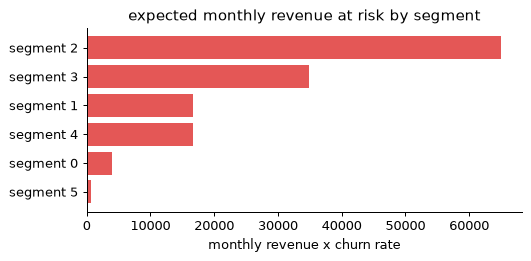

In [35]:
p2 = prof.sort_values("revenue_at_risk")
fig, ax = plt.subplots(figsize=(6, 3)); ax.barh(["segment " + str(i) for i in p2.index], p2.revenue_at_risk, color="#e45756")
ax.set_xlabel("monthly revenue x churn rate"); ax.set_title("expected monthly revenue at risk by segment"); plt.tight_layout(); plt.show()

## Part 5 · Churn model
**Rules set before looking at any test result:**
1. Split first (80/20, stratified, seed 42). The test set is touched **once**, at the end.
2. Anything that learns from data (scaler, one-hot encoder, model, calibration, threshold) is fitted on the training set only, inside a pipeline.
3. Features: only what a telco would know *before* the customer leaves. No `Churn` derivative, no `customerID`.
4. The model is chosen by cross-validated **log loss** (it measures probability quality, which the threshold step needs), with ROC-AUC and PR-AUC reported alongside.
5. Accuracy is not used: a model that says nobody churns is 73.5% accurate.

### 5.1 Split and feature table

In [36]:
from telco.model import add_features, split, logistic_pipeline, lgbm_pipeline, TARGET, ID, best_threshold, retention_value
full = add_features(clean_df)
X_train, X_test, y_train, y_test = split(full)
print("train", X_train.shape, f"churn {y_train.mean():.3f}", "| test", X_test.shape, f"churn {y_test.mean():.3f}")
print("added features:", [c for c in X_train.columns if c in ("n_addons", "monthly_vs_avg")])
assert TARGET not in X_train.columns and ID not in X_train.columns
assert set(X_train.index).isdisjoint(X_test.index)
print("leakage checks passed: no target, no ID, train/test disjoint")

train (5634, 21) churn 0.265 | test (1409, 21) churn 0.265
added features: ['n_addons', 'monthly_vs_avg']
leakage checks passed: no target, no ID, train/test disjoint


### 5.2 Cross-validation on the training set only: baseline vs logistic vs LightGBM

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score", "log_loss": "neg_log_loss"}
def run_cv(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    return {"model": name, **{k: -r["test_" + k].mean() if k in ("brier", "log_loss") else r["test_" + k].mean() for k in scoring},
            "roc_auc_std": r["test_roc_auc"].std()}
cv_rows = [run_cv("always-prior (dummy)", DummyClassifier(strategy="prior")),
           run_cv("logistic regression", logistic_pipeline(X_train)),
           run_cv("LightGBM (defaults)", lgbm_pipeline(X_train))]
pd.DataFrame(cv_rows).set_index("model").round(4)

,roc_auc,pr_auc,brier,log_loss,roc_auc_std
model,,,,,
always-prior (dummy),0.5000,0.2654,0.1949,0.5786,0.0000
logistic regression,0.8456,0.6591,0.1353,0.4173,0.0125
LightGBM (defaults),0.8329,0.6357,0.1428,0.4409,0.0082


### 5.3 Tuning LightGBM (randomized search, 5-fold CV inside the training set)
Small data and a noisy target mean the trees must be kept shallow and regularised; the search looks for that.

In [38]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV
space = {"clf__n_estimators": randint(80, 500), "clf__learning_rate": loguniform(0.01, 0.1), "clf__num_leaves": randint(4, 32),
         "clf__min_child_samples": randint(20, 120), "clf__subsample": uniform(0.6, 0.4), "clf__subsample_freq": [1],
         "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(0.1, 30)}
search = RandomizedSearchCV(lgbm_pipeline(X_train), space, n_iter=30, scoring="neg_log_loss", cv=cv, random_state=42, n_jobs=1, refit=True)
search.fit(X_train, y_train)
print("best CV log loss:", round(-search.best_score_, 4))
{k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}

best CV log loss: 0.4118


{'colsample_bytree': np.float64(0.5165),
 'learning_rate': np.float64(0.0221),
 'min_child_samples': 20,
 'n_estimators': 482,
 'num_leaves': 5,
 'reg_lambda': np.float64(2.0663),
 'subsample': np.float64(0.7791),
 'subsample_freq': 1}

In [39]:
tuned = search.best_estimator_
cv_rows.append(run_cv("LightGBM (tuned)", tuned))
cv_table = pd.DataFrame(cv_rows).set_index("model"); cv_table.round(4)

,roc_auc,pr_auc,brier,log_loss,roc_auc_std
model,,,,,
always-prior (dummy),0.5000,0.2654,0.1949,0.5786,0.0000
logistic regression,0.8456,0.6591,0.1353,0.4173,0.0125
LightGBM (defaults),0.8329,0.6357,0.1428,0.4409,0.0082
LightGBM (tuned),0.8494,0.6687,0.1338,0.4118,0.0110


### 5.4 Choose the model (rule fixed in advance: lowest CV log loss among logistic and tuned LightGBM)

In [40]:
cand = {"logistic regression": logistic_pipeline(X_train), "LightGBM (tuned)": tuned}
chosen_name = min(cand, key=lambda n: cv_table.loc[n, "log_loss"])
print("chosen by CV log loss:", chosen_name)
for n in cand: print(f"  {n:22s} CV log loss {cv_table.loc[n, 'log_loss']:.4f}  CV ROC-AUC {cv_table.loc[n, 'roc_auc']:.4f}")

chosen by CV log loss: LightGBM (tuned)
  logistic regression    CV log loss 0.4173  CV ROC-AUC 0.8456
  LightGBM (tuned)       CV log loss 0.4118  CV ROC-AUC 0.8494


## Part 6 · Evaluation on the held-out test set (first and only look)

In [41]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve, precision_recall_curve
fitted = {n: m.fit(X_train, y_train) for n, m in cand.items()}
proba = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
proba["always-prior (dummy)"] = np.full(len(y_test), y_train.mean())
def metrics(p): return {"roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p), "brier": brier_score_loss(y_test, p), "log_loss": log_loss(y_test, p)}
test_table = pd.DataFrame({n: metrics(p) for n, p in proba.items()}).T
test_table.round(4)

,roc_auc,pr_auc,brier,log_loss
logistic regression,0.8418,0.6341,0.1381,0.4206
LightGBM (tuned),0.8479,0.6640,0.1343,0.4129
always-prior (dummy),0.5000,0.2654,0.1950,0.5787


In [42]:
rng = np.random.default_rng(0); idx = np.arange(len(y_test)); yt = y_test.values
names = list(cand); boot = {n: [] for n in names}; diff = []
for _ in range(1000):
    s = rng.choice(idx, len(idx))
    if yt[s].min() == yt[s].max(): continue
    a = {n: roc_auc_score(yt[s], proba[n][s]) for n in names}
    for n in names: boot[n].append(a[n])
    diff.append(a[names[1]] - a[names[0]])
for n in names: print(f"{n:22s} test ROC-AUC {roc_auc_score(y_test, proba[n]):.3f}  95% CI [{np.percentile(boot[n], 2.5):.3f}, {np.percentile(boot[n], 97.5):.3f}]")
print(f"{names[1]} minus {names[0]}: median {np.median(diff):+.4f}, 95% CI [{np.percentile(diff, 2.5):+.4f}, {np.percentile(diff, 97.5):+.4f}]")

logistic regression    test ROC-AUC 0.842  95% CI [0.820, 0.862]
LightGBM (tuned)       test ROC-AUC 0.848  95% CI [0.825, 0.868]
LightGBM (tuned) minus logistic regression: median +0.0061, 95% CI [-0.0002, +0.0129]


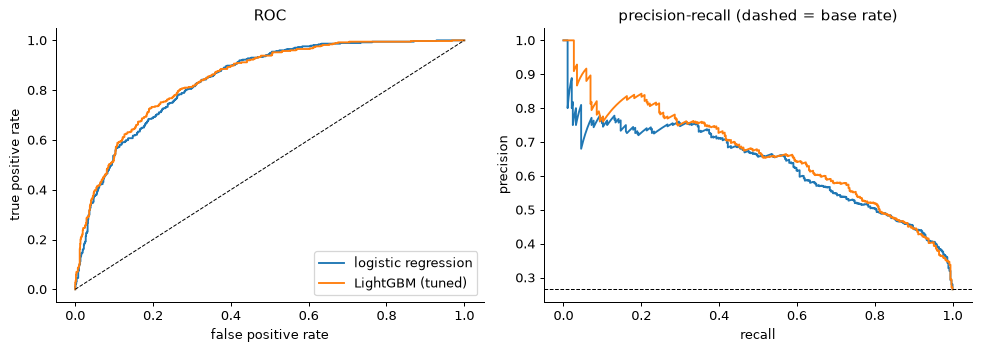

In [43]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for n in names:
    fpr, tpr, _ = roc_curve(y_test, proba[n]); axs[0].plot(fpr, tpr, label=n)
    pr, rc, _ = precision_recall_curve(y_test, proba[n]); axs[1].plot(rc, pr, label=n)
axs[0].plot([0, 1], [0, 1], "k--", lw=.8); axs[0].set_xlabel("false positive rate"); axs[0].set_ylabel("true positive rate"); axs[0].set_title("ROC"); axs[0].legend()
axs[1].axhline(y_test.mean(), color="k", ls="--", lw=.8); axs[1].set_xlabel("recall"); axs[1].set_ylabel("precision"); axs[1].set_title("precision-recall (dashed = base rate)")
plt.tight_layout(); plt.show()

### 6.1 Calibration: when the model says 40%, do 40% churn?

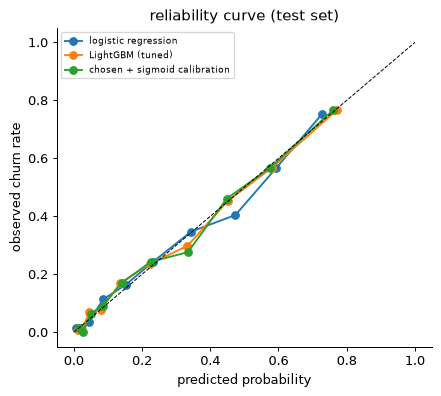

,brier,log_loss,roc_auc
logistic regression,0.1381,0.4206,0.8418
LightGBM (tuned),0.1343,0.4129,0.8479
chosen + sigmoid calibration,0.1342,0.4130,0.8482


In [44]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
best = fitted[chosen_name]
cal = CalibratedClassifierCV(cand[chosen_name], method="sigmoid", cv=5).fit(X_train, y_train)
proba["chosen + sigmoid calibration"] = cal.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(figsize=(5, 4.5))
for n in names + ["chosen + sigmoid calibration"]:
    fr, mp = calibration_curve(y_test, proba[n], n_bins=10, strategy="quantile"); ax.plot(mp, fr, "o-", label=n)
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("predicted probability"); ax.set_ylabel("observed churn rate"); ax.legend(fontsize=7); ax.set_title("reliability curve (test set)")
plt.tight_layout(); plt.show()
pd.DataFrame({n: metrics(proba[n]) for n in names + ["chosen + sigmoid calibration"]}).T[["brier", "log_loss", "roc_auc"]].round(4)

### 6.2 From probability to action: cost-based threshold
Contacting a customer costs money and only helps if they would have churned. **The numbers below are assumptions, not facts from the data** (a retention offer costs 20, saves 30% of the churners it reaches, and a saved customer is worth 12 months of their monthly charge). The threshold is picked on out-of-fold predictions from the *training* set, then applied once to the test set.

In [45]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(cand[chosen_name], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
thr, v_train = best_threshold(y_train, oof, X_train.MonthlyCharges)
print(f"threshold chosen on training out-of-fold predictions: {thr:.2f}")
pt = proba[chosen_name]; m_test = X_test.MonthlyCharges
def summary(label, t):
    contacted = pt >= t; tp = (contacted & (y_test.values == 1)).sum()
    return {"strategy": label, "contacted": int(contacted.sum()), "churners reached": int(tp), "precision": tp / max(contacted.sum(), 1),
            "recall": tp / y_test.sum(), "net value": retention_value(y_test, pt, m_test, t)}
strat = pd.DataFrame([summary("contact nobody", 1.01), summary("contact everyone", 0.0), summary("default threshold 0.5", 0.5), summary(f"cost-based threshold {thr:.2f}", thr)]).set_index("strategy")
strat.round(3)

threshold chosen on training out-of-fold predictions: 0.06


,contacted,churners reached,precision,recall,net value
strategy,,,,,
contact nobody,0,0,0.000,0.000,0.00
contact everyone,1409,374,0.265,1.000,69793.64
default threshold 0.5,288,191,0.663,0.511,46744.74
cost-based threshold 0.06,990,362,0.366,0.968,75686.58


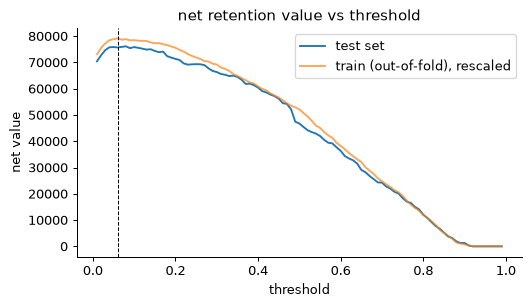

In [46]:
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
fig, ax = plt.subplots(figsize=(6, 3.5)); ax.plot(grid, [retention_value(y_test, pt, m_test, t) for t in grid], label="test set")
ax.plot(grid, [retention_value(y_train, oof, X_train.MonthlyCharges, t) * len(y_test) / len(y_train) for t in grid], label="train (out-of-fold), rescaled", alpha=.7)
ax.axvline(thr, color="k", ls="--", lw=.8); ax.set_xlabel("threshold"); ax.set_ylabel("net value"); ax.set_title("net retention value vs threshold"); ax.legend(); plt.tight_layout(); plt.show()

How sensitive is the answer to the assumptions? Net value on the test set at the threshold chosen under each assumption pair:

In [47]:
rows = []
for sr in (0.1, 0.2, 0.3, 0.5):
    for cost in (10, 20, 50):
        t, _ = best_threshold(y_train, oof, X_train.MonthlyCharges, save_rate=sr, cost=cost)
        rows.append({"save_rate": sr, "offer_cost": cost, "threshold": t,
                     "net_value_test": retention_value(y_test, pt, m_test, t, save_rate=sr, cost=cost),
                     "contact_everyone": retention_value(y_test, pt, m_test, 0.0, save_rate=sr, cost=cost)})
pd.DataFrame(rows).round(2)

,save_rate,offer_cost,threshold,net_value_test,contact_everyone
0,0.1,10,0.13,22351.02,18567.88
1,0.1,20,0.20,14885.50,4477.88
2,0.1,50,0.50,3101.58,-37792.12
3,0.2,10,0.06,53757.72,51225.76
4,0.2,20,0.13,44702.04,37135.76
5,0.2,50,0.30,24599.08,-5134.24
6,0.3,10,0.04,86560.20,83883.64
7,0.3,20,0.06,75686.58,69793.64
8,0.3,50,0.18,51540.34,27523.64
9,0.5,10,0.04,151467.00,149199.40


### 6.3 What drives the predictions? (SHAP on the tuned LightGBM)

C:\Users\mahmoud\Downloads\telco-customer-intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


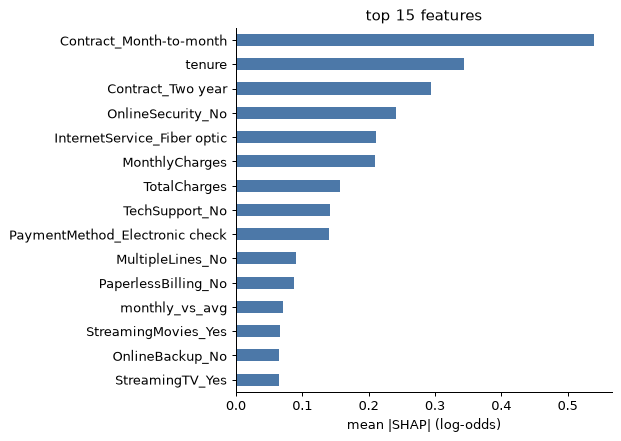

Contract_Month-to-month           0.540
tenure                            0.344
Contract_Two year                 0.294
OnlineSecurity_No                 0.242
InternetService_Fiber optic       0.211
MonthlyCharges                    0.210
TotalCharges                      0.157
TechSupport_No                    0.142
PaymentMethod_Electronic check    0.140
MultipleLines_No                  0.090
dtype: float64

In [48]:
import shap
lg = fitted["LightGBM (tuned)"]
Xt = pd.DataFrame(lg.named_steps["prep"].transform(X_test), columns=lg.named_steps["prep"].get_feature_names_out())
sv = shap.TreeExplainer(lg.named_steps["clf"])(Xt).values
sv = sv[:, :, 1] if sv.ndim == 3 else sv
imp = pd.Series(np.abs(sv).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
imp.index = [i.replace("num__", "").replace("cat__", "") for i in imp.index]
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color="#4c78a8"); ax.set_xlabel("mean |SHAP| (log-odds)"); ax.set_title("top 15 features"); plt.tight_layout(); plt.show()
imp.head(10).round(3)

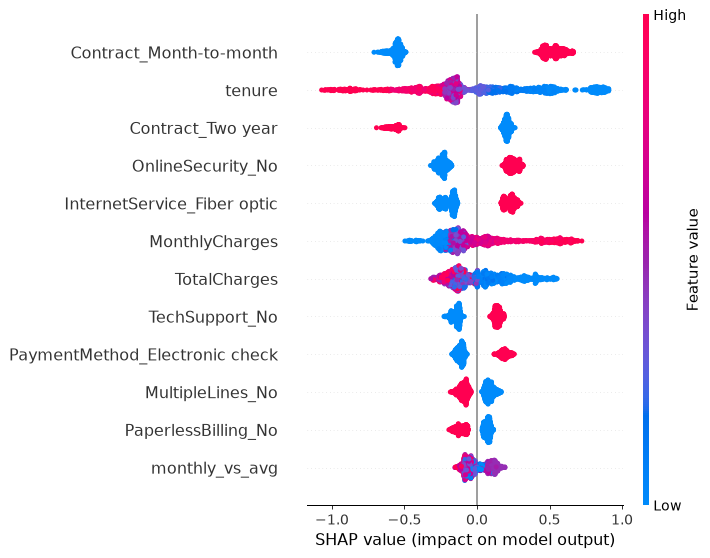

In [49]:
shap.summary_plot(sv, Xt.rename(columns=lambda c: c.replace("num__", "").replace("cat__", "")), max_display=12, show=False); plt.tight_layout(); plt.show()

### What the evaluation shows
| | CV ROC-AUC (train, 5-fold) | Test ROC-AUC | Test PR-AUC | Test log loss |
|---|---|---|---|---|
| always-prior baseline | 0.500 | 0.500 | 0.265 | 0.579 |
| logistic regression | 0.846 | 0.842 [0.820, 0.862] | 0.634 | 0.421 |
| LightGBM, defaults | 0.833 | not evaluated on test | | |
| **LightGBM, tuned** (chosen) | **0.849** | **0.848 [0.825, 0.868]** | **0.664** | **0.413** |

1. **The tuned boosted model is not clearly better than logistic regression.** The paired bootstrap difference in test AUC is +0.006 with a 95% interval of [-0.0002, +0.013], which touches zero. Untuned LightGBM was actually *worse* than logistic (CV AUC 0.833 vs 0.846). The gain came from tuning (shallow trees, strong regularisation) on a small, mostly linear problem. A fair summary: ROC-AUC about 0.85, and a simple model is nearly as good.
2. **Calibration is good for both models.** Predicted and observed churn rates track the diagonal. Sigmoid calibration changed nothing (Brier 0.1343 to 0.1342), so it is not used.
3. **The cost-based threshold (0.06) beats the default 0.5, but only modestly beats contacting everyone.** On the test set: net value 75.7k at threshold 0.06, 69.8k for contacting everyone (+8%), 46.7k at 0.5. At 0.06 the model reaches 97% of churners (precision 37%); at 0.5 it reaches only 51% (precision 66%). With a cheap offer (cost 20 against roughly 60 of expected saving per average customer contacted) nearly everyone is worth contacting. **The model earns its keep when contact is expensive:** at cost 50 and save rate 0.3 it nets 51.5k vs 27.5k for a blanket campaign, and at save rate 0.1 and cost 50 it is +3.1k vs -37.8k. All of this rests on assumed numbers (cost, save rate, 12-month value), not on data.
4. **What drives the predictions (SHAP):** month-to-month contract, short tenure, no two-year contract, no online security, fiber, and monthly charges. This agrees with the statistics and the EDA. SHAP explains the model, not the customers: it does not show that changing a feature would change behaviour.

**Limits of this result:** single snapshot and a single 1,409-row test set (so about +/-0.02 on AUC); `tenure` for churners is time until they left while for active customers it is time so far, so the model separates "left" from "still here" rather than truly predicting the future; a public sample dataset, not DemoTel's real customers; the money assumptions are invented.

## Part 7 · Model benchmark: which algorithm is better?
**Question:** does any model family beat the others on this data, and is XGBoost really better than logistic regression?

**Protocol (fixed before running):**
- 9 models from 6 families: baseline, linear (logistic), distance (kNN), neural net (MLP), bagged trees (random forest, extra trees) and boosted trees (sklearn HistGradientBoosting, XGBoost, LightGBM).
- Same preprocessing family, same training set, **same 5 outer folds** for everyone.
- **Nested CV:** inside each outer training fold every tunable model gets the same budget (12 random configurations, 3-fold inner CV, scored by log loss). The outer fold is never used for tuning, so tuned models are not favoured over untuned ones.
- Ranking metric: log loss (probability quality); ROC-AUC and PR-AUC are reported too. Differences are compared **fold by fold** (paired), because the folds share data.
- The test set is *not* used to rank. It is shown at the end for reference only.

In [50]:
import time
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from telco.benchmark import candidates
cands = candidates(X_train)
rows, secs = [], {}
for name, (pipe, space) in cands.items():
    t0 = time.perf_counter()
    for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
        model = clone(pipe)
        if space:
            model = RandomizedSearchCV(model, space, n_iter=12, scoring="neg_log_loss", cv=3, random_state=k, n_jobs=1)
        model.fit(X_train.iloc[tr], y_train.iloc[tr])
        p = model.predict_proba(X_train.iloc[va])[:, 1]; yv = y_train.iloc[va]
        rows.append({"model": name, "fold": k, "roc_auc": roc_auc_score(yv, p), "pr_auc": average_precision_score(yv, p),
                     "brier": brier_score_loss(yv, p), "log_loss": log_loss(yv, p)})
    secs[name] = time.perf_counter() - t0
    print(f"{name:32s} done in {secs[name]:5.0f}s")
bench = pd.DataFrame(rows)

dummy (prior)                    done in     0s


logistic regression              done in    10s


k-nearest neighbours             done in    13s


MLP (neural net)                 done in    41s


random forest                    done in   125s


extra trees                      done in   126s


HistGradientBoosting (sklearn)   done in    90s


XGBoost                          done in    46s


LightGBM                         done in    62s


### 7.1 Results: mean and spread over the 5 outer folds (sorted by log loss, best first)

In [51]:
g = bench.groupby("model")
summ = pd.DataFrame({"log_loss": g.log_loss.mean(), "log_loss_sd": g.log_loss.std(), "roc_auc": g.roc_auc.mean(), "roc_auc_sd": g.roc_auc.std(),
                     "pr_auc": g.pr_auc.mean(), "brier": g.brier.mean(), "minutes (incl. tuning)": pd.Series(secs) / 60}).sort_values("log_loss")
summ.round(4)

,log_loss,log_loss_sd,roc_auc,roc_auc_sd,pr_auc,brier,minutes (incl. tuning)
XGBoost,0.4112,0.0127,0.8500,0.0122,0.6689,0.1335,0.7729
LightGBM,0.4122,0.0127,0.8490,0.0116,0.6684,0.1339,1.0334
HistGradientBoosting (sklearn),0.4163,0.0104,0.8458,0.0096,0.6614,0.1351,1.5033
random forest,0.4166,0.0074,0.8453,0.0085,0.6601,0.1351,2.0845
logistic regression,0.4171,0.0140,0.8458,0.0141,0.6585,0.1353,0.1645
extra trees,0.4194,0.0084,0.8438,0.0096,0.6548,0.1364,2.0953
MLP (neural net),0.4257,0.0148,0.8390,0.0136,0.6495,0.1380,0.6903
k-nearest neighbours,0.4387,0.0181,0.8345,0.0098,0.6213,0.1418,0.2177
dummy (prior),0.5786,0.0001,0.5000,0.0000,0.2654,0.1949,0.0032


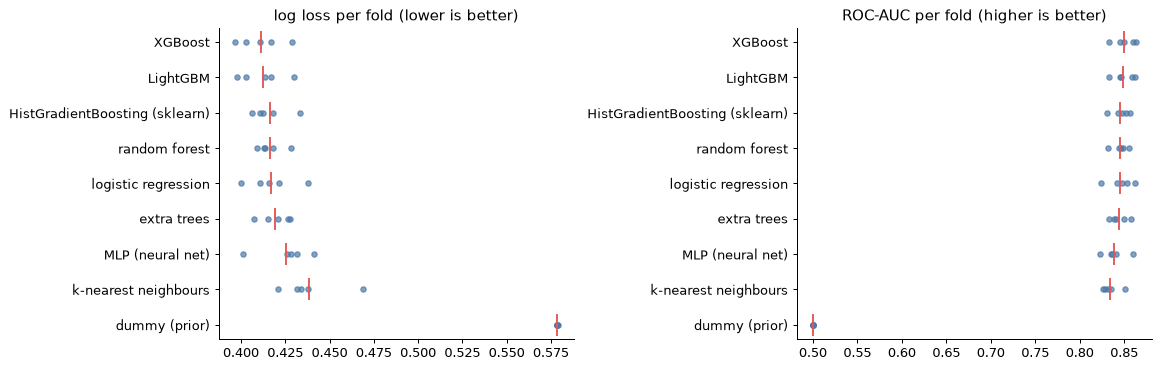

In [52]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2)); order = list(summ.index)
for ax, metric, title in [(axs[0], "log_loss", "log loss per fold (lower is better)"), (axs[1], "roc_auc", "ROC-AUC per fold (higher is better)")]:
    for i, n in enumerate(order):
        v = bench[bench.model == n][metric]; ax.scatter(v, [i] * len(v), s=18, color="#4c78a8", alpha=.7); ax.scatter(v.mean(), i, marker="|", s=300, color="#e45756")
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis(); ax.set_title(title)
plt.tight_layout(); plt.show()

### 7.2 Paired comparison: is the best model actually better than the simple baseline (logistic regression)?

In [53]:
ll = bench.pivot(index="fold", columns="model", values="log_loss"); auc = bench.pivot(index="fold", columns="model", values="roc_auc")
rows = []
for n in order:
    if n == "logistic regression": continue
    d_ll, d_auc = ll[n] - ll["logistic regression"], auc[n] - auc["logistic regression"]
    rows.append({"model": n, "mean log-loss diff": d_ll.mean(), "folds better (log loss)": int((d_ll < 0).sum()), "mean AUC diff": d_auc.mean(), "folds better (AUC)": int((d_auc > 0).sum())})
pd.DataFrame(rows).set_index("model").round(4)

,mean log-loss diff,folds better (log loss),mean AUC diff,folds better (AUC)
model,,,,
XGBoost,-0.0059,4,0.0042,4
LightGBM,-0.0049,4,0.0033,4
HistGradientBoosting (sklearn),-0.0008,2,0.0001,2
random forest,-0.0006,3,-0.0005,3
extra trees,0.0023,2,-0.0020,1
MLP (neural net),0.0085,0,-0.0068,0
k-nearest neighbours,0.0216,0,-0.0113,1
dummy (prior),0.1615,0,-0.3458,0


### 7.3 For reference only: the held-out test set (not used to choose)

In [54]:
rows = []
for name, (pipe, space) in cands.items():
    model = clone(pipe)
    if space: model = RandomizedSearchCV(model, space, n_iter=12, scoring="neg_log_loss", cv=3, random_state=0, n_jobs=1)
    p = model.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    rows.append({"model": name, **metrics(p)})
test_bench = pd.DataFrame(rows).set_index("model").loc[order]
test_bench.round(4)

,roc_auc,pr_auc,brier,log_loss
model,,,,
XGBoost,0.8455,0.6650,0.1352,0.4153
LightGBM,0.8485,0.6639,0.1342,0.4126
HistGradientBoosting (sklearn),0.8471,0.6642,0.1349,0.4148
random forest,0.8453,0.6596,0.1353,0.4154
logistic regression,0.8411,0.6276,0.1385,0.4214
extra trees,0.8377,0.6418,0.1386,0.4245
MLP (neural net),0.8396,0.6377,0.1388,0.4233
k-nearest neighbours,0.8278,0.6137,0.1447,0.4617
dummy (prior),0.5000,0.2654,0.1950,0.5787


### What the benchmark shows
**Ranking by nested-CV log loss (5 outer folds, tuned fairly):**

| Rank | Model | Log loss | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| 1 | XGBoost | 0.4112 | 0.850 | 0.669 |
| 2 | LightGBM | 0.4122 | 0.849 | 0.668 |
| 3 | HistGradientBoosting | 0.4163 | 0.846 | 0.661 |
| 4 | random forest | 0.4166 | 0.845 | 0.660 |
| 5 | logistic regression | 0.4171 | 0.846 | 0.659 |
| 6 | extra trees | 0.4194 | 0.844 | 0.655 |
| 7 | MLP | 0.4257 | 0.839 | 0.650 |
| 8 | k-nearest neighbours | 0.4387 | 0.835 | 0.621 |
| 9 | dummy | 0.5786 | 0.500 | 0.265 |

1. **XGBoost is nominally first, but the evidence for "better" is weak.** Against logistic regression it improves log loss by 0.0059 and wins 4 of 5 folds, yet the fold-to-fold spread (sd about 0.013) is twice the gap. XGBoost and LightGBM differ by 0.001: they are the same result. Five folds are too few for a meaningful significance test, so the honest reading is *"boosted trees are probably slightly better, by about 0.004 AUC"*.
2. **Three tiers.** (a) XGBoost and LightGBM; (b) HistGradientBoosting, random forest and logistic regression, all within 0.001 log loss; (c) extra trees, the MLP and kNN, which are worse. A regularised linear model is as good as a random forest here, which fits the earlier finding that the signal is mostly additive (contract, tenure, internet type).
3. **The test set does not confirm the order.** On the held-out test set LightGBM is first (log loss 0.4126), XGBoost third (0.4153), and the boosted/forest group is again within 0.003. A flip like that between two models CV rates as equal is what noise looks like (1,409 rows, AUC good to about +/-0.02). This is why the test set was not used for ranking. Logistic regression is consistently a little behind on the test set (log loss 0.4214, PR-AUC 0.628 vs about 0.66).
4. **Cost matters.** XGBoost took about 0.8 minutes (including tuning) against 0.16 for logistic regression and 2.1 for the forests. For a gain of about 0.004 AUC that is a real trade-off in a production setting where the model is retrained often.
5. **Sanity check:** the nested log loss of tuned LightGBM (0.4122) is almost the same as the non-nested value from Part 5 (0.4118), so the earlier tuning was not noticeably over-optimistic.

**Decision:** keep a boosted tree (XGBoost or LightGBM) as the production candidate, with regularised logistic regression kept as the explainable, near-equal fallback. No algorithm family wins by a margin that matters more than the data limits (single snapshot, AUC ceiling around 0.85). Gains from here come from better features or more data, not from trying more algorithms.
